# Análisis de clientes de ConnectaTel

**Proyecto del Bootcamp de Análisis de Datos de TripleTen (2026)**

ConnectaTel es una empresa de telecomunicaciones en Latinoamérica. En este análisis se exploran, limpian y analizan los datos de sus clientes y de su uso real de llamadas y mensajes durante 2024, para construir un perfil estadístico de los usuarios, detectar comportamientos atípicos y crear segmentos de clientes que orienten estrategias de retención y mejoras en los planes.

**Datasets**

- `plans.csv`: planes actuales (precio, minutos, mensajes y GB incluidos, y costo por consumo extra).
- `users_latam.csv`: 4.000 clientes (edad, ciudad, fecha de registro, plan y fecha de cancelación).
- `usage.csv`: 40.000 eventos de uso (llamadas con su duración y mensajes con su longitud).

Los hallazgos y recomendaciones se resumen en la sección 7.

## 1. Carga y exploración de los datos

### 1.1 Carga de datos y vista rápida

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Estructura de los datasets

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


## 2. Problemas de calidad de datos

### 2.1 Valores nulos

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print((users.isna().sum()/ len(users)) * 100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print((usage.isna().sum()/ len(usage)) * 100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


**Diagnóstico de valores nulos**

- `users.city`: 469 nulos (11,7 %). Está en el rango de 5–30 %, así que antes de decidir revisaré en el paso 2.2 si hay otros valores que también representen datos faltantes.
- `users.churn_date`: 3.534 nulos (88,4 %). No es un error: un nulo significa que el cliente sigue activo. Se conserva como nulo, porque la columna es clave para analizar la cancelación.
- `usage.date`: 50 nulos (0,125 %). Se dejan como nulos: el análisis por usuario cuenta eventos y no depende de la fecha, y eliminarlos haría perder 50 eventos reales.
- `usage.duration` (55,2 %) y `usage.length` (44,7 %): la proporción es alta, pero probablemente depende de `type`, ya que la duración solo aplica a llamadas y la longitud a mensajes. Se verificará antes de decidir.


### 2.2 Valores inválidos y sentinels

In [12]:
# 1. Resumen estadístico de todas las columnas numéricas
display(users.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T)

# Valores iguales a -999
print('age = -999:', (users['age'] == -999).sum())

# Todos los valores negativos (incluye los -999)
print('age < 0:', (users['age'] < 0).sum())

# Si hay negativos distintos de -999, verlos
print(users.loc[(users['age'] < 0) & (users['age'] != -999), 'age'].value_counts())

,count,mean,std,min,5%,25%,50%,75%,95%,max
user_id,4000.0,11999.50000,1154.844867,10000.0,10199.95,10999.75,11999.5,12999.25,13799.05,13999.0
age,4000.0,33.73975,123.232257,-999.0,20.00,32.00,47.0,63.00,76.00,79.0


age = -999: 55
age < 0: 55
Series([], Name: age, dtype: int64)


- La columna `user_id` Corresponde a una clave primaria o identificador único de cada usuario. Se distribuye de forma perfectamente regular y secuencial a lo largo de los $4\,000$ registros, iniciando en $10\,000.0$ y finalizando en $13\,999.0$. Al observar los percentiles (el 5% en $10\,199.95$, el 25% en $10\,999.75$, la mediana o 50% en $11\,999.5$, el 75% en $12\,999.25$ y el 95% en $13\,799.05$), se evidencia un espaciado equidistante. Al tratarse exclusivamente de un número de identificación de clientes, sus parámetros matemáticos (como la media de $11\,999.5$ o la desviación estándar de $1\,154.84$) no representan propiedades del negocio ni tienen significado analítico real.
- La columna `age` Presenta una grave distorsión por la presencia de un código centinela o valor atípico extremo. El valor mínimo se ubica en $-999.0$, el cual claramente no corresponde a una edad física real, sino a una codificación utilizada por el sistema transaccional para indicar datos faltantes o no capturados. Se encontro que este valor aparece 55 veces en la base de datos siendo el unico valor atipico dentro de 'age'.  Este valor negativo extremo deforma fuertemente los estadísticos globales: reduce artificialmente el promedio general a tan solo $33.74$ años e infla la desviación estándar hasta $123.23$. No obstante, a partir del percentil 5 los datos se comportan de forma biológica y comercialmente coherente: el percentil 5 se ubica en $20$ años, el 25% en $32$ años, la mediana (percentil 50) en $47$ años, el 75% en $63$ años y el 95% en $76$ años, alcanzando una edad máxima razonable de $79$ años. Por ende, resulta indispensable tratar o filtrar estos registros con valores menores o iguales a $0$ (reemplazándolos por NaN o imputándolos) antes de proceder con segmentaciones o análisis demográficos.

In [13]:
# explorar columnas numéricas de usage
print(usage[['id', 'user_id', 'duration', 'length']].describe())

# Valores más altos de cada métrica, para ver si hay saltos
print(usage['duration'].nlargest(35))
print(usage['length'].nlargest(35))

# ¿Cuántas veces aparecen los valores sospechosos?
print('duration = 120:', (usage['duration'] == 120).sum())
print('length = 1490:', (usage['length'] == 1490).sum())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000
1414     120.00
1824     120.00
1932     120.00
2832     120.00
2894     120.00
2972     120.00
3986     120.00
8265     120.00
11456    120.00
12921    120.00
13235    120.00
14128    120.00
15517    120.00
16702    120.00
19360    120.00
20237    120.00
20500    120.00
22814    120.00
23052    120.00
23451    120.00
26561    120.00
27171    120.00
28921    120.00
30212    120.00
32432    120.00
32632    120.00
36587    120.00
37562    120.00
389

- Las columnas id y user_id, representan las claves de identificación técnica y relacional del registro y del cliente respectivamente, por lo que sus medidas estadísticas (como media, desviación estándar o cuartiles) no poseen un significado numérico ni de negocio directo; mientras que id es una clave primaria consecutiva y completa para las $40\,000$ transacciones (con valores del $1.0$ al $40\,000.0$), user_id actúa como una clave foránea (foreign key) distribuida uniformemente entre los identificadores $10\,000$ y $13\,999$, permitiendo vincular los consumos con la base demográfica de usuarios para posteriores análisis agrupados.
- Para la columna duration el valor 120 aparece 30 veces y es el máximo de la columna. Después de 120, el siguiente valor más alto es 46,98, sin valores intermedios. Es un sentinel.
- Para la columna length: el valor 1.490 aparece 30 veces y es el máximo. Después de 1.490, el siguiente valor es 125. También es un sentinel.


In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

# 1. Resumen descriptivo general de las columnas categóricas
print(users[columnas_user].describe())
print("-" * 50)

# 2. Conteo de frecuencias y valores únicos por columna
for col in columnas_user:
    print(f"Distribución de frecuencias para '{col}':")
    print(users[col].value_counts(dropna=False))
    print(f"Total de categorías únicas: {users[col].nunique(dropna=False)}\n")



          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595
--------------------------------------------------
Distribución de frecuencias para 'city':
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Total de categorías únicas: 8

Distribución de frecuencias para 'plan':
Basico     2595
Premium    1405
Name: plan, dtype: int64
Total de categorías únicas: 2



- La columna city presenta 469 valores nulos (NaN), equivalentes al 11.73% de la base ademas se identificaron 96 registros con el valor '?' (un 2.40% adicional). Ambos casos corresponden a registros sin ciudad identificada, sumando un total de 565 registros sin ubicación válida (14.13%). Se propone representar ambos casos como nulos, para que todos los faltantes queden registrados de la misma forma sin perder usuarios válidos. 
- La columna plan esta completamente limpia se puede interpretar que, la mayoría de la base de usuarios pertenece al plan de entrada, lo que ofrece una oportunidad clara para campañas de upselling hacia el segmento Premium.

In [15]:

# Explorar columna categórica de usage
print(usage['type'].value_counts(dropna=False))
# Cruce de los sentinels con el tipo de evento
print('duration = 120 por tipo:')
print(usage[usage['duration'] == 120]['type'].value_counts())
print('length = 1490 por tipo:')
print(usage[usage['length'] == 1490]['type'].value_counts())

# Registros con ambas columnas llenas
ambos = usage['duration'].notna() & usage['length'].notna()
print('Registros con duration y length a la vez:', ambos.sum())

text    22092
call    17908
Name: type, dtype: int64
duration = 120 por tipo:
text    16
call    14
Name: type, dtype: int64
length = 1490 por tipo:
text    18
call    12
Name: type, dtype: int64
Registros con duration y length a la vez: 28


- La columna type Clasifica la naturaleza del evento registrado en dos modalidades del servicio (call y text), pero evidencia inconsistencias operativas de captura cruzada y datos atípicos extremos: aunque el $99.93\%$ del volumen cumple la correspondencia estructural esperada, existen 28 registros anómalos que contienen simultáneamente valores en duration y length. Además, los valores máximos del dataset se distribuyen de forma errónea entre ambas categorías: para la duración máxima de $120$ minutos, $16$ registros corresponden a text y $14$ a call, mientras que para la longitud máxima de $1\,490$ caracteres, $18$ transacciones corresponden a text y $12$ a call. Esto confirma fallas puntuales en la telemetría del sistema origen donde se traslaparon o intercambiaron las métricas de ambos tipos de evento, requiriendo una depuración condicional para dejar como nula la métrica que no corresponda al tipo de servicio asignado.


**Diagnóstico de valores inválidos y sentinels**

Columnas con valores inválidos o sentinels:

- **`age` (`users`):** el valor `-999` aparece en 55 registros. No es una edad posible, sino un código para un dato faltante, y distorsiona el promedio y la dispersión de la columna.
- **`city` (`users`):** el valor `'?'` aparece en 96 registros (2,40 %) y representa una ciudad desconocida. Sumado a los 469 nulos, deja 565 registros sin ubicación válida (14,13 %).
- **`duration` y `length` (`usage`):** el valor 120 aparece 30 veces en `duration` y el 1.490 otras 30 en `length`. En ambos casos es el máximo de la columna y está aislado del resto: después de 120, la llamada más larga dura 46,98 minutos, y después de 1.490, el mensaje más largo tiene 125 caracteres. Estos sentinels también explican los 28 registros con ambas columnas llenas: los mensajes tienen `duration` = 120 y las llamadas `length` = 1.490.

Acciones:

- **`age`:** reemplazar `-999` por la mediana de la edad, para conservar a los usuarios sin distorsionar la distribución.
- **`city`:** reemplazar `'?'` por nulos (`pd.NA`), para que todos los faltantes estén representados igual. No se imputará una ciudad, ya que no es una variable central para la segmentación.
- **`duration` y `length`:** reemplazar los valores 120 y 1.490 por nulos (`NaN`), sin eliminar los registros, porque el evento sí ocurrió y debe contar en la actividad del usuario. No se usarán ceros, porque representarían llamadas o mensajes reales de duración o longitud cero.

### 2.3 Revisión de fechas

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
users['reg_date'].dtype

dtype('<M8[ns]')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
usage['date'].dtype

dtype('<M8[ns]')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, los registros se reparten de forma casi igual entre 2022 (1.314), 2023 (1.316) y 2024 (1.330). Sin embargo, aparecen **40 registros con año 2026** (1,0 % de los usuarios), una fecha imposible, porque los datos llegan hasta 2024.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, los 39.950 registros con fecha corresponden a 2024, lo que coincide con el periodo del análisis. No hay años fuera de rango; los únicos problemas son los 50 valores nulos ya identificados en el paso 2.1.  
Basaremos el análisis en estas fechas.

**Diagnóstico de fechas fuera de rango**

- **`reg_date`:** sí hay años imposibles: 40 usuarios con fecha de registro en 2026. Se marcarán como nulos (`pd.NaT`) sin eliminar a los usuarios, ya que el resto de su información es válida y la fecha de registro no se usa en la segmentación.
- **`date`:** no hay fechas fuera de rango. Los 50 nulos se mantienen, porque el análisis cuenta eventos por usuario y no depende de la fecha.


## 3. Limpieza de datos

### 3.1 Corrección de sentinels y fechas imposibles

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print('Mediana usada:', age_mediana)
users['age'].describe()

Mediana usada: 48.0


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print('Valores "?" restantes:', (users['city'] == '?').sum())
print('Nulos en city:', users['city'].isna().sum())


Valores "?" restantes: 0
Nulos en city: 565


In [22]:
# Marcar fechas futuras como NA para reg_date
# En columnas de fecha, el nulo se representa con pd.NaT
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


In [23]:
# Corregir sentinels de usage (sin eliminar registros)
# 1. Valores que no corresponden al tipo de registro (28 cruzados)
usage.loc[usage['type'] == 'call', 'length'] = np.nan
usage.loc[usage['type'] == 'text', 'duration'] = np.nan

# 2. Sentinels restantes dentro de su tipo (14 llamadas y 18 mensajes)
usage.loc[usage['duration'] == 120, 'duration'] = np.nan
usage.loc[usage['length'] == 1490, 'length'] = np.nan

# Verificar cambios
print(usage.groupby('type')[['duration', 'length']].count())
print(usage[['duration', 'length']].max())

      duration  length
type                  
call     17894       0
text         0   22074
duration     46.98
length      125.00
dtype: float64


### 3.2 Tratamiento de nulos en `duration` y `length`

In [24]:

# Verificación MAR en usage (Missing At Random) para duration
# Proporción de nulos en duration según el tipo de evento
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean())

type
call    0.000782
text    1.000000
Name: duration, dtype: float64

In [25]:
# Verificación MAR en usage (Missing At Random) para length
# Proporción de nulos en length según el tipo de evento
usage.groupby('type')['length'].apply(lambda x: x.isna().mean())


type
call    1.000000
text    0.000815
Name: length, dtype: float64

**Diagnóstico de nulos en `duration` y `length`**

Los nulos dependen por completo de `type`: `duration` es nula en el 100 % de los mensajes y `length` en el 100 % de las llamadas, porque cada métrica solo aplica a un tipo de evento. Por lo tanto, son nulos MAR (Missing At Random) y se dejan como nulos.

Los únicos nulos dentro del tipo correcto son los sentinels que se limpiaron en el paso 3.1: 14 llamadas sin duración (0,08 %) y 18 mensajes sin longitud (0,08 %). Su impacto es mínimo, y para contar eventos por usuario se usan las columnas `is_call` e `is_text`, que no dependen de estos nulos.

## 4. Uso por usuario

### 4.1 Agrupación por usuario

Se resume la actividad de cada usuario en 2024: cantidad de mensajes, cantidad de llamadas y minutos totales de llamada.

In [26]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
# Se cuentan eventos con is_text e is_call (no con duration o length, que tienen nulos)
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Combinar la tabla agregada con el dataset de usuarios
# left join: se conservan todos los usuarios, incluso los que no registran uso
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Los usuarios sin eventos tienen 0 mensajes, llamadas y minutos
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print('Usuarios sin registros de uso:', user_profile['cant_mensajes'].isna().sum())
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

user_profile.head(5)

Usuarios sin registros de uso: 1


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario

In [29]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,22.411225
std,17.689919,2.359738,2.145139,15.053351
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.080000
50%,48.000000,5.000000,4.000000,19.670000
75%,63.000000,7.000000,6.000000,30.992500
max,79.000000,17.000000,15.000000,105.540000


In [30]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True).mul(100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

## 5. Distribuciones y outliers

### 5.1 Distribuciones por plan

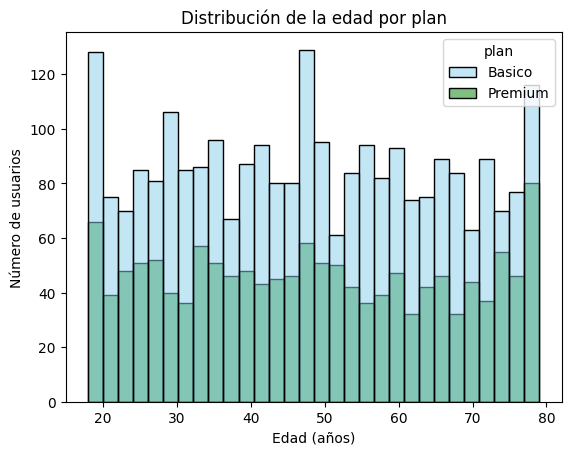

In [31]:
# Histograma para visualizar age
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- **Distribución:** la edad se reparte de forma casi uniforme entre los 18 y los 79 años, sin un sesgo claro. La barra más alta cerca de los 48 años se explica en parte por los 55 usuarios a los que se les imputó la mediana (48).
- **Plan:** la proporción de usuarios Premium es parecida en todas las edades, así que la edad no parece influir en la elección del plan.

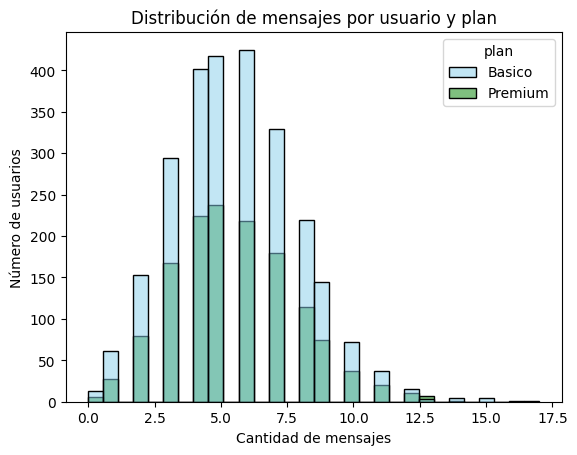

In [32]:
# Histograma para visualizar cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de mensajes por usuario y plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- **Distribución:** ligeramente sesgada a la derecha. La mayoría de los usuarios envió entre 4 y 7 mensajes en 2024 (mediana de 5), y pocos superan los 11.
- **Plan:** los usuarios Básico y Premium tienen una distribución casi idéntica. Pagar el plan Premium, que incluye 500 mensajes frente a 100, no se traduce en un mayor uso de mensajes.

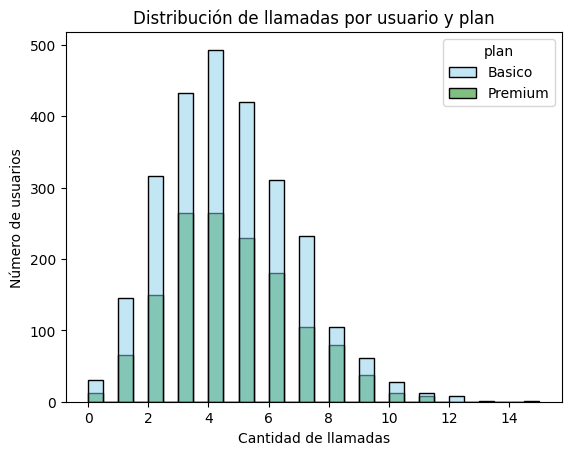

In [33]:
# Histograma para visualizar cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de llamadas por usuario y plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- **Distribución:** ligeramente sesgada a la derecha. La mayoría hizo entre 3 y 6 llamadas en 2024 (mediana de 4), y muy pocos superan las 10.
- **Plan:** la forma es similar en ambos planes, aunque los usuarios Premium están proporcionalmente más presentes a partir de unas 8 llamadas. Hay una leve tendencia a que los Premium llamen un poco más.

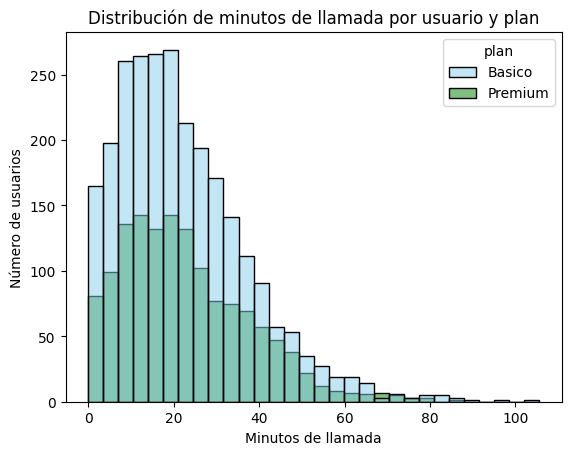

In [34]:
# Histograma para visualizar cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de minutos de llamada por usuario y plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- **Distribución:** claramente sesgada a la derecha. La mayoría acumula entre 11 y 31 minutos en el año (mediana de 19,7), con una cola larga que llega a 105 minutos.
- **Plan:** en los niveles más altos de minutos, la proporción de usuarios Premium es mayor que en el resto de la distribución. Aun así, el consumo de ambos planes está muy por debajo de los minutos que incluyen (100 en Básico y 600 en Premium).

### 5.2 Outliers

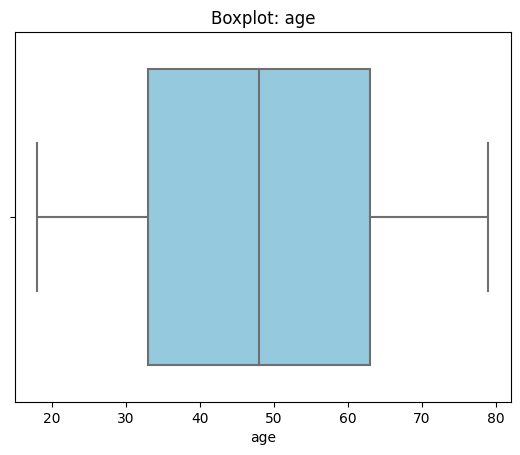

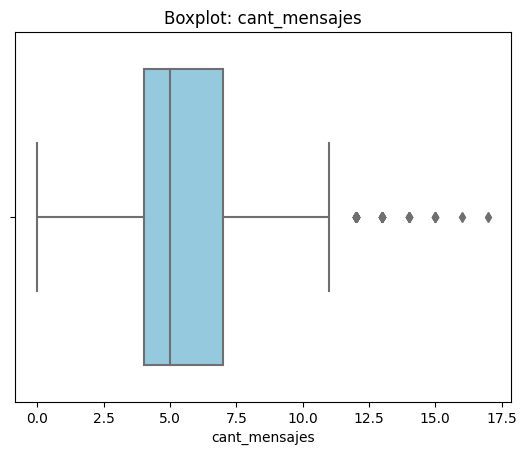

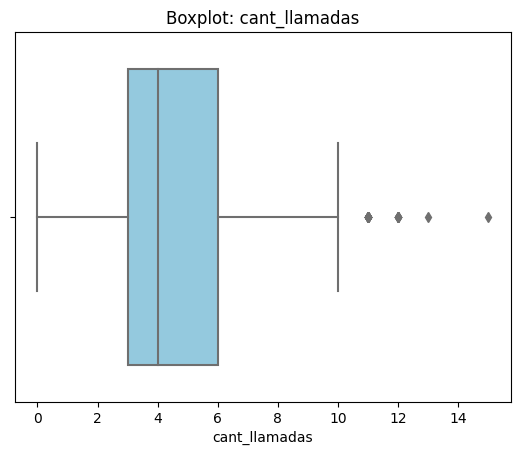

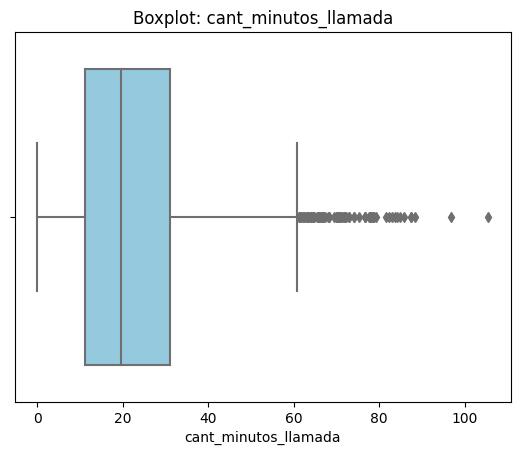

In [35]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- **Age:** no presenta outliers; todas las edades están entre 18 y 79 años.
- **cant_mensajes:** presenta outliers solo hacia arriba, usuarios con más de 11 mensajes (máximo de 17).
- **cant_llamadas:** presenta outliers solo hacia arriba, usuarios con más de 10 llamadas (máximo de 15).
- **cant_minutos_llamada:** presenta la mayor cantidad de outliers, todos hacia arriba, con usuarios de más de 61 minutos (máximo de 105,5).

In [36]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f'{col}: límite superior = {limite_superior:.2f} | outliers = {n_outliers}')

cant_mensajes: límite superior = 11.50 | outliers = 46
cant_llamadas: límite superior = 10.50 | outliers = 30
cant_minutos_llamada: límite superior = 60.86 | outliers = 84


In [37]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.411225
std,2.359738,2.145139,15.053351
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.080000
50%,5.000000,4.000000,19.670000
75%,7.000000,6.000000,30.992500
max,17.000000,15.000000,105.540000


💡Insights: 
- **cant_mensajes:** mantener los 46 outliers (límite de 11,5). Son valores posibles (hasta 17 mensajes) y representan a los usuarios más activos, no errores de captura.
- **cant_llamadas:** mantener los 30 outliers (límite de 10,5). Un máximo de 15 llamadas es un comportamiento real y está cerca del límite.
- **cant_minutos_llamada:** mantener los 84 outliers (límite de 60,9). Los sentinels de 120 minutos ya se limpiaron, así que estos valores (hasta 105,5) corresponden a usuarios que realmente hablan más. Eliminarlos haría desaparecer justo al segmento de mayor consumo, que es clave para la segmentación.

## 6. Segmentación de clientes

### 6.1 Segmentación por uso

- **Bajo uso:** menos de 5 llamadas y menos de 5 mensajes.
- **Uso medio:** menos de 10 llamadas y menos de 10 mensajes.
- **Alto uso:** el resto de los usuarios.

In [38]:
# Crear columna grupo_uso
# El orden importa: primero el caso general y después los más restrictivos
user_profile['grupo_uso'] = 'Alto uso'
user_profile.loc[(user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'grupo_uso'] = 'Uso medio'
user_profile.loc[(user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'grupo_uso'] = 'Bajo uso'

In [39]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación por edad

- **Joven:** menos de 30 años.
- **Adulto:** de 30 a 59 años.
- **Adulto mayor:** 60 años o más.

In [40]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = 'Adulto Mayor'
user_profile.loc[user_profile['age'] < 60, 'grupo_edad'] = 'Adulto'
user_profile.loc[user_profile['age'] < 30, 'grupo_edad'] = 'Joven'

In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Distribución de los segmentos

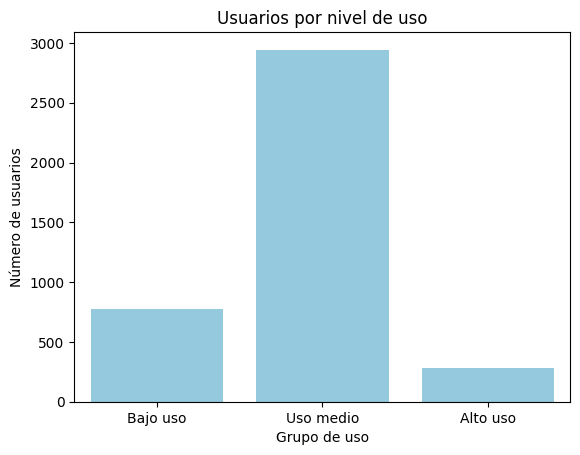

In [42]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Usuarios por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Número de usuarios')
plt.show()

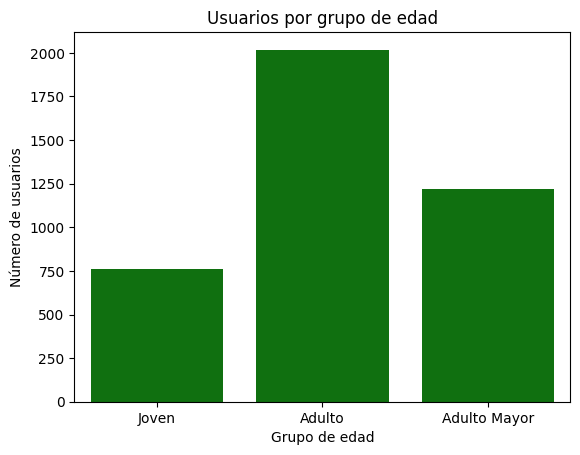

In [43]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='green')
plt.title('Usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Número de usuarios')
plt.show()

## 7. Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- **`age`:** 55 usuarios (1,4 %) tenían el sentinel `-999`; se reemplazó por la mediana (48 años).
- **`city`:** 565 usuarios (14,1 %) sin ciudad válida: 469 nulos y 96 con `'?'`. Se dejaron como nulos.
- **`reg_date`:** 40 usuarios (1,0 %) con fecha de registro en 2026, imposible porque los datos llegan hasta 2024. Se marcaron como nulos.
- **`date`:** 50 eventos (0,125 %) sin fecha; se conservaron porque el análisis cuenta eventos por usuario.
- **`duration` y `length`:** el sistema registró valores de relleno (120 minutos y 1.490 caracteres) en 30 eventos de cada columna, incluidos 28 eventos con la métrica del tipo equivocado. Se reemplazaron por nulos sin eliminar los eventos.

🔍 **Segmentos por Edad**
- Los adultos (30 a 59 años) son el grupo principal, con cerca de la mitad de los usuarios; le siguen los adultos mayores (alrededor del 30 %) y los jóvenes (alrededor del 19 %).
- La edad no cambia la elección de plan: la proporción de usuarios Premium es similar en todas las edades.

📊 **Segmentos por Nivel de Uso**
- Cerca de 3 de cada 4 usuarios están en uso medio, alrededor del 19 % en bajo uso y solo cerca del 7 % en alto uso.
- Los usuarios Premium tienden a concentrarse en los niveles más altos de llamadas y minutos, pero su uso de mensajes es igual al de los usuarios Básico.
- Los outliers (46 en mensajes, 30 en llamadas y 84 en minutos) son usuarios reales de alto consumo, no errores, y forman el segmento más valioso para ofertas de mayor valor.

➡️ Esto sugiere que el consumo de casi todos los clientes está muy por debajo de lo que incluyen sus planes: el usuario típico hizo 4 llamadas, 19,7 minutos y 5 mensajes en 2024, frente a los 100 minutos y 100 mensajes del plan Básico. El plan Premium cuesta más del doble (USD 25 frente a USD 12), pero sus usuarios no aprovechan esa diferencia, lo que puede generar la sensación de pagar de más y aumentar el riesgo de cancelación.

💡 **Recomendaciones**
- **Revisar el valor del plan Premium:** reforzarlo con beneficios que los clientes sí usen o ajustar su precio, ya que el volumen de minutos y mensajes incluido no es lo que lo diferencia en la práctica.
- **Crear un plan de entrada más económico** para el segmento de bajo uso (cerca del 19 %), que hoy paga por capacidad que no utiliza.
- **Enfocar las campañas de upselling en el segmento de alto uso con plan Básico,** que es el que más se beneficiaría de un plan superior.
- **Analizar la cancelación por segmento:** el 11,7 % de los clientes canceló; cruzar `churn_date` con el plan y el nivel de uso permitiría saber si los clientes Premium de bajo uso abandonan más.
- **Mejorar la captura de datos:** corregir el registro de la ciudad (14 % sin dato) y los valores de relleno del sistema, para que los próximos análisis sean más confiables.

**Limitación:** el dataset de uso no incluye el consumo de datos (GB), que es uno de los componentes principales de los planes, así que la evaluación de los planes se basa solo en llamadas y mensajes.